Brianna Aceves | DSC355 | Project Milestone 4

Dataset used: Animal Charity: Wildlife Conservation Donations dataset from Kaggle. 

In [1]:
#import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)

In [2]:
#load the dataset
df = pd.read_csv("animal_charity_donation_records.csv")

df.head()

,donor_id,age_group,gender,name,email,country,donation_type,donation_amount,donation_date,payment_method,newsletter_opt_in,referral_channel,sector,campaign
0,1a3d1fa7-bc89-40a9-a3b8-c1e9392456de,50-65,Female,Allison Hill,allison.hill40@yahoo.com,UK,Monthly,115.31,2024-10-24,Paypal,False,Website,Real Estate,Rescue Orphaned Gorillas
1,3b8faa18-37f8-488b-97fc-695a07a0ca6e,50-65,Female,Angie Henderson,angie.henderson758@gmail.com,USA,One-time,8.60,2024-06-21,Bank Transfer,False,Online advertising,Logistics,Rescue Orphaned Gorillas
2,72ff5d2a-386e-4be0-ab65-a6a48b8148f6,50-65,Female,Christina Santos,christina.santos275@gmail.com,USA,One-time,40.07,2024-08-21,Bank Transfer,False,Online advertising,Media & Communication,Marine Mammal Defense Mission
3,47229389-571a-4876-ac30-7511b2b9437a,18-29,Male,Aaron Shaffer,aaron.shaffer1@hotmail.com,USA,One-time,45.17,2023-10-09,Bank Transfer,False,Online advertising,Government,Wildlife Rescue Van Drive
4,580d7b71-d8f5-4413-9be6-128e18c26797,30-49,Female,Gabrielle Davis,gabrielle.davis890@yahoo.com,UK,One-time,85.84,2024-09-01,Bank Transfer,True,Newsletter,Science & Research,Habitat for Hope


In [3]:
#dataset overview
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn Names:")
print(df.columns.tolist())

Number of rows: 10000
Number of columns: 14

Column Names:
['donor_id', 'age_group', 'gender', 'name', 'email', 'country', 'donation_type', 'donation_amount', 'donation_date', 'payment_method', 'newsletter_opt_in', 'referral_channel', 'sector', 'campaign']


My Initial Data Review: The dataset contains 10,000 donation records and 14 variables. The variables include donor information, donation behavior, engagement information, and campaign information. The dataset is small enough to work with efficiently while still providing enough observations to explore patterns in donor behavior. One important observation is that each "donor_id" is unique. Because there are no repeated donor IDs, I cannot directly track an individual donor's giving behavior over time. This is why I will use "donation_type" as the target and examine differences between monthly and one-time donors.

In [4]:
#review variable types and dataset information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   donor_id           10000 non-null  object 
 1   age_group          10000 non-null  object 
 2   gender             10000 non-null  object 
 3   name               10000 non-null  object 
 4   email              10000 non-null  object 
 5   country            10000 non-null  object 
 6   donation_type      10000 non-null  object 
 7   donation_amount    10000 non-null  float64
 8   donation_date      10000 non-null  object 
 9   payment_method     10000 non-null  object 
 10  newsletter_opt_in  10000 non-null  bool   
 11  referral_channel   10000 non-null  object 
 12  sector             10000 non-null  object 
 13  campaign           10000 non-null  object 
dtypes: bool(1), float64(1), object(12)
memory usage: 1.0+ MB


In [5]:
#separate numerical and categorical variables
numeric_columns = df.select_dtypes(include=np.number).columns
categorical_columns = df.select_dtypes(
    include=["object", "bool"]
).columns

print("Numerical Variables:")
print(numeric_columns.tolist())

print("\nCategorical Variables:")
print(categorical_columns.tolist())

Numerical Variables:
['donation_amount']

Categorical Variables:
['donor_id', 'age_group', 'gender', 'name', 'email', 'country', 'donation_type', 'donation_date', 'payment_method', 'newsletter_opt_in', 'referral_channel', 'sector', 'campaign']


Most of the variables in this dataset are categorical. Examples include age group, gender, country, donation type, payment method, referral channel, sector, and campaign. The "newsletter_opt_in" is a Boolean variable whether that donor opted in to receive newsletters. The "donation_amount" is the main numerical variable. The donation date is currently stored as text, so I will convert it to a date format before continuing the analysis. The "donor_id", name, and email columns identify individual donors not individual giving so it's not relevant here.

In [6]:
#convert donation_date
df["donation_date"] = pd.to_datetime(df["donation_date"])

df["donation_date"].dtype

dtype('<M8[ns]')

In [7]:
#create date features for EDA
df["donation_year"] = df["donation_date"].dt.year
df["donation_month"] = df["donation_date"].dt.month
df["donation_dayofweek"] = df["donation_date"].dt.day_name()

The "donation_date" variable was originally stored as text, so I converted it to a datetime format. I also created year, month, and day-of-week variables. These features make it easier to explore whether donation behavior changes over time.

In [8]:
#descriptive statistics for donation amount
df["donation_amount"].describe()

count    10000.000000
mean        51.696998
std         56.745420
min          0.550000
25%         12.070000
50%         28.110000
75%         71.592500
max        702.930000
Name: donation_amount, dtype: float64

Descriptive Statistics:
The average donation is approximately 51.70. The median donation donation amount is 28.11. The fact that the mean is obviously higher than the median suggests that donation amounts may be right-skewed, with some larger donations increasing the average. Donation amounts range from 0.55 to 702.93. The large difference between the typical donation and the maximum donation also suggests that there may be some high-value donations that appear as potential outliers.

In [9]:
#check for missing values
missing_values = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Percent Missing": (df.isnull().sum() / len(df) * 100).round(2)
})

missing_values

,Missing Values,Percent Missing
donor_id,0,0.0
age_group,0,0.0
gender,0,0.0
name,0,0.0
email,0,0.0
country,0,0.0
donation_type,0,0.0
donation_amount,0,0.0
donation_date,0,0.0
payment_method,0,0.0


There are no missing values in the dataset.

In [10]:
#check for duplicates
print("Number of duplicate rows:", df.duplicated().sum())

# Check whether donor IDs are repeated
print("Unique donor IDs:", df["donor_id"].nunique())

Number of duplicate rows: 0
Unique donor IDs: 10000


There are no duplicate rows in the dataset, and all 10,000 donor IDs are unique. This means each row represents a different donor.
This means that the "donor_id", "name", and "email" variables are going to be useful for identifying individual records, but they are not particularly useful predictive features for this project. Including these variables could add unnecessary information without describing meaningful donor behavior, so I would exclude them from future predictive modeling.

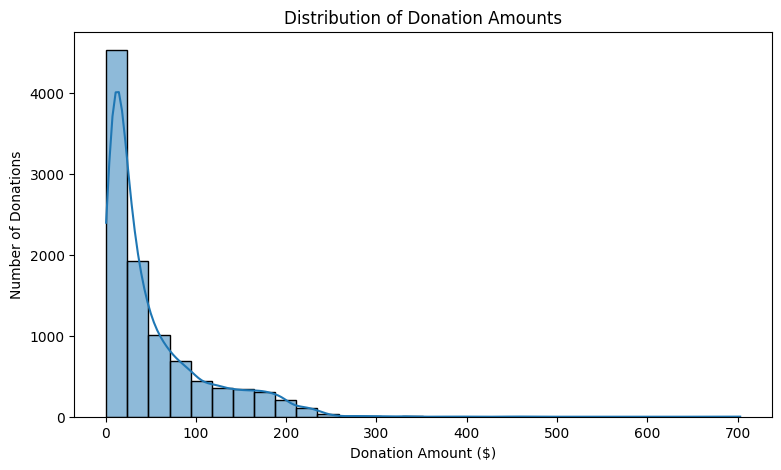

In [11]:
#number of donations by amount of donation given
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="donation_amount",
    bins=30,
    kde=True
)

plt.title("Distribution of Donation Amounts")
plt.xlabel("Donation Amount ($)")
plt.ylabel("Number of Donations")
plt.show()

The donation amount distribution is right-skewed. Most donations are toward the lower end of the range (under 100.00), while a smaller number of donors gave much larger amounts. This explains why the average donation is higher than the median. This pattern makes sense for charitable giving because many donors may donate smaller amounts while a smaller group gives a larger donation.

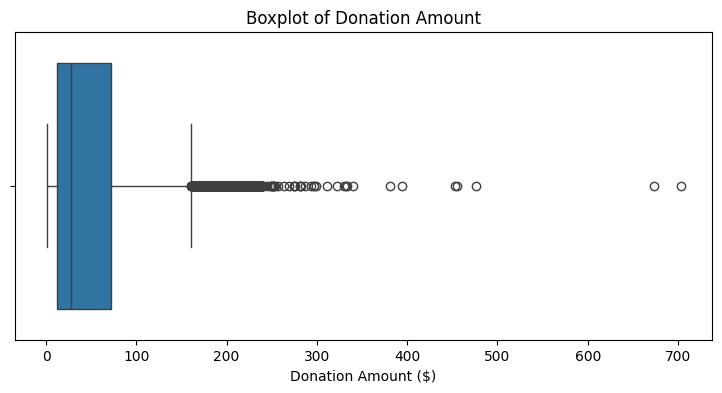

In [12]:
#look for outliers via boxplot
plt.figure(figsize=(9, 4))

sns.boxplot(
    data=df,
    x="donation_amount"
)

plt.title("Boxplot of Donation Amount")
plt.xlabel("Donation Amount ($)")
plt.show()

The boxplot shows several high donation amounts that may be considered statistical outliers. However, I wouldn't automatically remove these outliers. Large donations are realistic in fundraising data and could represent high-value donors rather than data-entry errors. Before modeling, I may consider whether transforming the donation amount or using a model that is less sensitive to extreme values would be more appropriate than deleting these records altogether.

In [13]:
#examine the target variable
df["donation_type"].value_counts()

donation_type
One-time    7085
Monthly     2915
Name: count, dtype: int64

In [14]:
#percentages
df["donation_type"].value_counts(normalize=True).mul(100).round(2)

donation_type
One-time    70.85
Monthly     29.15
Name: proportion, dtype: float64

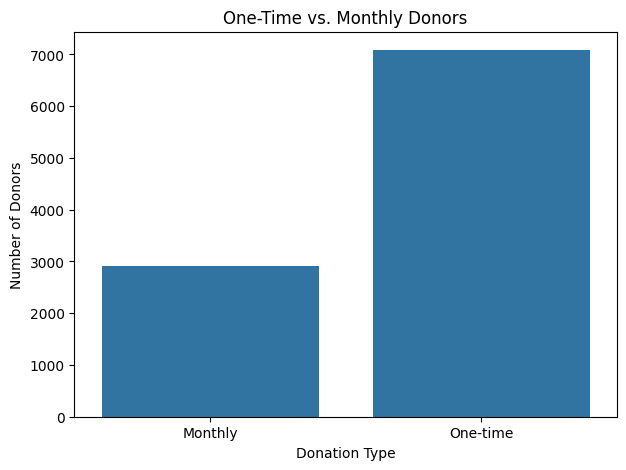

In [15]:
#graph the target variable information
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="donation_type"
)

plt.title("One-Time vs. Monthly Donors")
plt.xlabel("Donation Type")
plt.ylabel("Number of Donors")
plt.show()

The target variable is the "donation_type". About 70.85% of the records are one-time donations, while 29.15% are monthly donations. This essentially shows that one-time donors are much more common in the dataset. The target is somewhat imbalanced, which will be important to consider when building a predictive model. Accuracy alone may not be enough to evaluate the model because a model could favor the larger one-time donor group.

In [16]:
#distribution by category
categorical_features = [
    "age_group",
    "gender",
    "country",
    "payment_method",
    "newsletter_opt_in",
    "referral_channel",
    "campaign"
]

for column in categorical_features:
    print(f"\n--- {column} ---")
    print(df[column].value_counts())


--- age_group ---
age_group
30-49    4011
50-65    3401
18-29    1432
66-80    1156
Name: count, dtype: int64

--- gender ---
gender
Male      4908
Female    4697
Other      395
Name: count, dtype: int64

--- country ---
country
USA             2146
UK              1380
France          1103
Germany          998
Canada           844
Australia        650
South Africa     523
New Zealand      508
India            504
Brazil           490
Netherlands      476
Finland          378
Name: count, dtype: int64

--- payment_method ---
payment_method
Paypal           2576
Bank Transfer    2494
Credit Card      2477
Cheque           2453
Name: count, dtype: int64

--- newsletter_opt_in ---
newsletter_opt_in
False    5008
True     4992
Name: count, dtype: int64

--- referral_channel ---
referral_channel
Word of mouth         1788
Newsletter            1659
Website               1654
Local event           1653
Online advertising    1639
Social Media          1607
Name: count, dtype: int64

--- camp

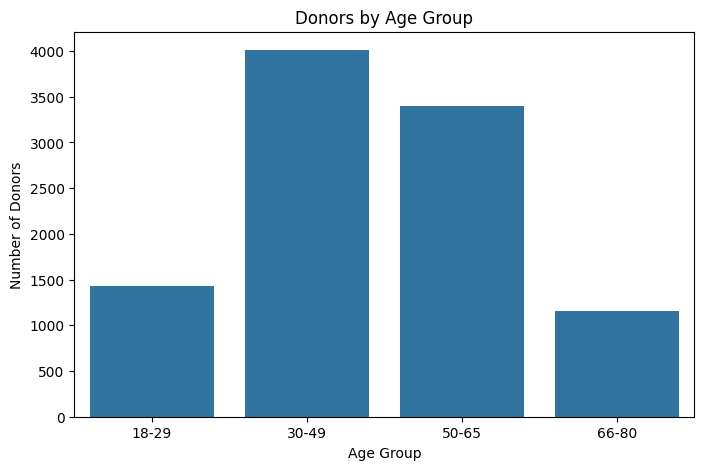

In [17]:
#age distribution
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="age_group",
    order=["18-29", "30-49", "50-65", "66-80"]
)

plt.title("Donors by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Donors")
plt.show()

The largest donor age group is 30-49, followed by donors between 50-65. The 18-29 and 66-80 groups appear less frequently in the dataset.
This shows that the donor population is not evenly distributed across age groups. Age group may be worth comparing with donation type to see whether monthly giving is more common among certain age groups.

In [18]:
#bivariate EDA: age vs target variable
age_donation = pd.crosstab(
    df["age_group"],
    df["donation_type"],
    normalize="index"
) * 100

age_donation.round(2)

donation_type,Monthly,One-time
age_group,,
18-29,28.56,71.44
30-49,28.95,71.05
50-65,29.46,70.54
66-80,29.67,70.33


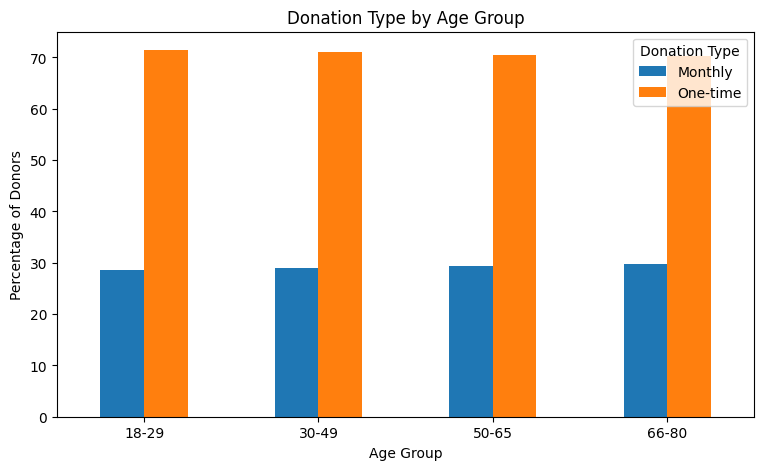

In [19]:
#graph of comparison
age_donation.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Donation Type by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Percentage of Donors")
plt.xticks(rotation=0)
plt.legend(title="Donation Type")
plt.show()

Again, the age distribution shows that most donors are between the ages of 30-49, followed by the 50-65 age group. The 18-29 and 66-80 groups contain fewer donors. This means the dataset is not evenly distributed across age groups. Because the middle-aged groups contain more donors, I want to be careful not to assume that age automatically leads to monthly giving. I will compare age with donation type and donation amount to see whether there are meaningful differences.

In [20]:
#compare newsletter vs. target variable 
newsletter_donation = pd.crosstab(
    df["newsletter_opt_in"],
    df["donation_type"],
    normalize="index"
) * 100

newsletter_donation.round(2)

donation_type,Monthly,One-time
newsletter_opt_in,,
False,28.65,71.35
True,29.65,70.35


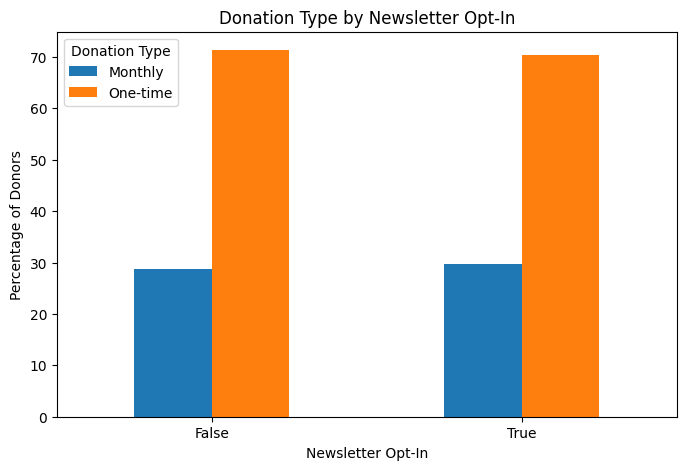

In [21]:
newsletter_donation.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Donation Type by Newsletter Opt-In")
plt.xlabel("Newsletter Opt-In")
plt.ylabel("Percentage of Donors")
plt.xticks(rotation=0)
plt.legend(title="Donation Type")
plt.show()

Newsletter participation does not appear to have a strong relationship with donation type. Donors who opted into the newsletter and those who did not have very similar percentages of monthly and one-time donations so it appears to be insignificant. In both groups, around 70% of donors are one-time donors and around 30% are monthly donors. This suggests that newsletter participation by itself may not be a strong predictor of whether someone becomes a monthly donor.

In [22]:
#compare donation amount given vs target variable
df.groupby("donation_type")["donation_amount"].describe()

,count,mean,std,min,25%,50%,75%,max
donation_type,,,,,,,,
Monthly,2915.0,100.013822,61.901497,2.55,47.205,91.87,150.885,239.87
One-time,7085.0,31.817881,40.162005,0.55,9.430,18.89,38.410,702.93


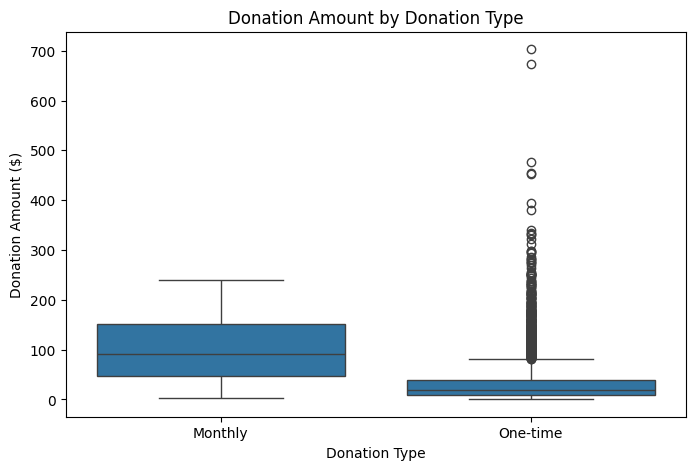

In [23]:
#plot the comparison
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="donation_type",
    y="donation_amount"
)

plt.title("Donation Amount by Donation Type")
plt.xlabel("Donation Type")
plt.ylabel("Donation Amount ($)")
plt.show()

The boxplot shows a difference in donation amounts between monthly and one-time donors. Monthly donors generally have higher donation amounts, with a much higher median than one-time donors. One-time donations are usually smaller, but this group also contains many high-value outliers, including a few donations above 400 dollars and even 700 dollars. This suggests that a donor can still make a very large donation without becoming a monthly donor. Overall, donation amount appears to have a stronger relationship with donation type than many of the other features I've looked at so far.

In [24]:
#compare referral vs target variable
referral_donation = pd.crosstab(
    df["referral_channel"],
    df["donation_type"],
    normalize="index"
) * 100

referral_donation.round(2)

donation_type,Monthly,One-time
referral_channel,,
Local event,29.70,70.30
Newsletter,27.91,72.09
Online advertising,29.59,70.41
Social Media,30.12,69.88
Website,26.72,73.28
Word of mouth,30.76,69.24


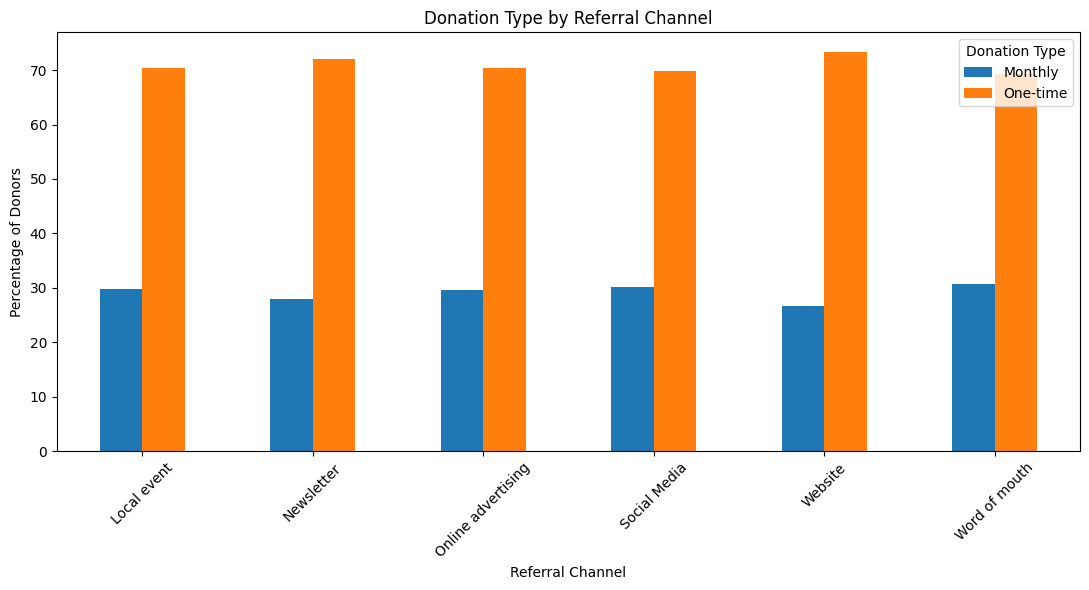

In [25]:
#graph to show how many donors are coming from referrals
referral_donation.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Donation Type by Referral Channel")
plt.xlabel("Referral Channel")
plt.ylabel("Percentage of Donors")
plt.xticks(rotation=45)
plt.legend(title="Donation Type")
plt.tight_layout()
plt.show()

Donation patterns are fairly similar across the different referral channels. One-time donations make up around 70% or more of the donations for each channel, while monthly donations generally remain around 30%. Word of mouth and social media appear to have slightly higher percentages of monthly donors, while the website appears slightly lower. However, these differences are small. Based on this graph alone, referral channel does not appear to have a major relationship with whether someone becomes a monthly donor.

In [26]:
#compare campaign vs target variable
campaign_donation = pd.crosstab(
    df["campaign"],
    df["donation_type"],
    normalize="index"
) * 100

campaign_donation.round(2)

donation_type,Monthly,One-time
campaign,,
Defend the Great Apes,30.57,69.43
Habitat for Hope,28.25,71.75
Jungle Education Project,29.39,70.61
Marine Mammal Defense Mission,28.06,71.94
Reforest the Sanctuary,30.09,69.91
Rescue Orphaned Gorillas,28.20,71.80
Wildlife Rescue Van Drive,29.54,70.46


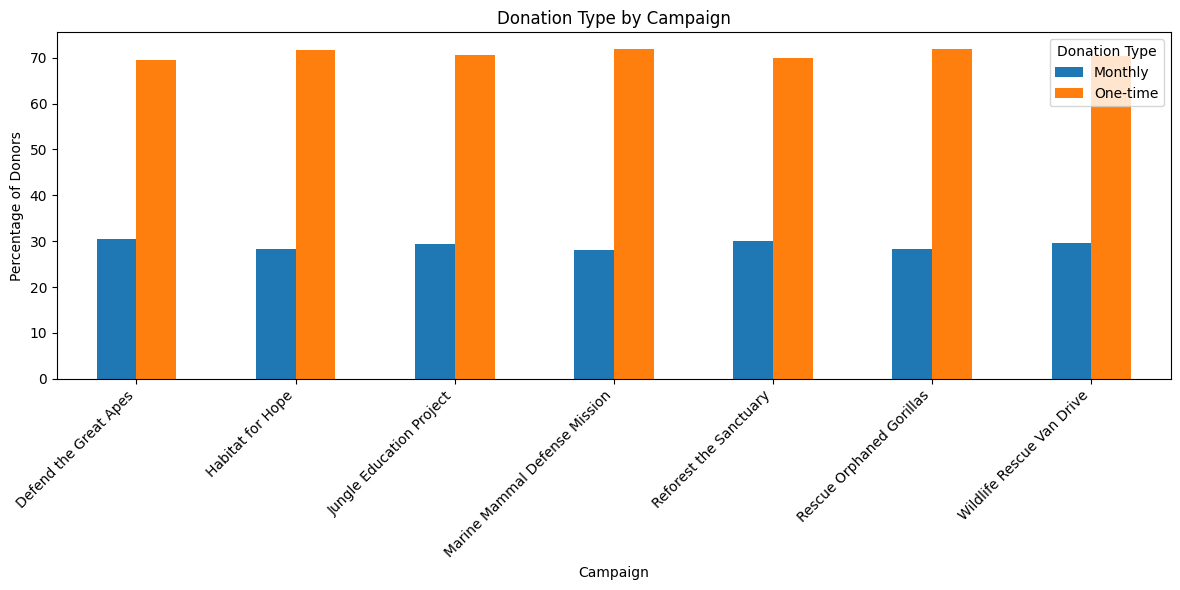

In [27]:
#graph to show the comparison
campaign_donation.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Donation Type by Campaign")
plt.xlabel("Campaign")
plt.ylabel("Percentage of Donors")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Donation Type")
plt.tight_layout()
plt.show()

The percentage of monthly and one-time donors is also similar across the different campaigns. Each campaign has approximately 28-30% monthly donors and around 70-72% one-time donors. There are small differences between campaigns, but none of them appear large enough to show a clear relationship with monthly giving. This suggests that campaign choice may provide less predictive information than a feature such as donation amount and its probably insignificant for review.

In [28]:
#create numerical versions of certain variables
df["monthly_donor"] = df["donation_type"].map({
    "One-time": 0,
    "Monthly": 1
})

df["newsletter_numeric"] = df["newsletter_opt_in"].astype(int)

df["age_group_numeric"] = df["age_group"].map({
    "18-29": 1,
    "30-49": 2,
    "50-65": 3,
    "66-80": 4
})

Prep Variables for Correlation Analysis: Most variables in this dataset are categorical, so a standard correlation matrix cannot be used directly to all of them. To make a basic correlation comparison possible, I created numerical versions of donation type, newsletter participation, and age group. For "monthly_donor", one-time donations are represented by 0 and monthly donations by 1. Newsletter participation is also represented by 0 and 1. Age groups are ordered from the youngest to oldest. These variables will allow me to explore whether there are noticeable linear relationships with donation amount and monthly giving.

In [29]:
#Correlation Matrix
correlation_features = [
    "donation_amount",
    "monthly_donor",
    "newsletter_numeric",
    "age_group_numeric"
]

correlation_matrix = df[correlation_features].corr()

correlation_matrix.round(3)

,donation_amount,monthly_donor,newsletter_numeric,age_group_numeric
donation_amount,1.000,0.546,0.007,0.140
monthly_donor,0.546,1.000,0.011,0.008
newsletter_numeric,0.007,0.011,1.000,-0.008
age_group_numeric,0.140,0.008,-0.008,1.000


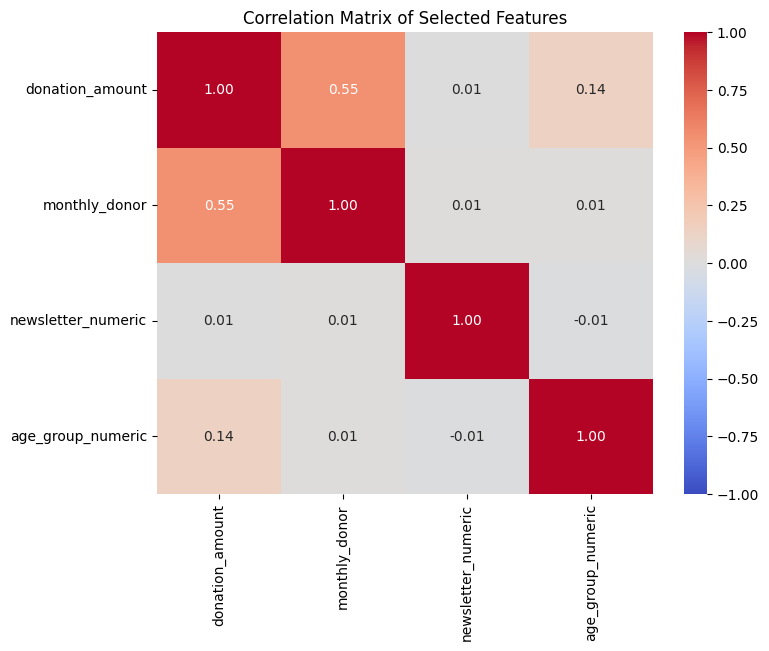

In [30]:
#graph matrix
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Matrix of Selected Features")
plt.show()

The correlation matrix shows that donation amount has the strongest relationship with monthly donor status, with a positive correlation of 0.55. This supports what I observed in the boxplots, where monthly donors generally gave higher amounts than one-time donors. Age group has a weak positive correlation of 0.14 with donation amount, meaning donation amounts may increase slightly across the older age groups. However, age group has only a 0.01 correlation with monthly donor status. Newsletter participation also has only a 0.01 correlation with monthly donor status and donation amount. Overall, most of the selected variables have very weak relationships with one another. Donation amount stands out as the feature with the clearest relationship to the target variable.

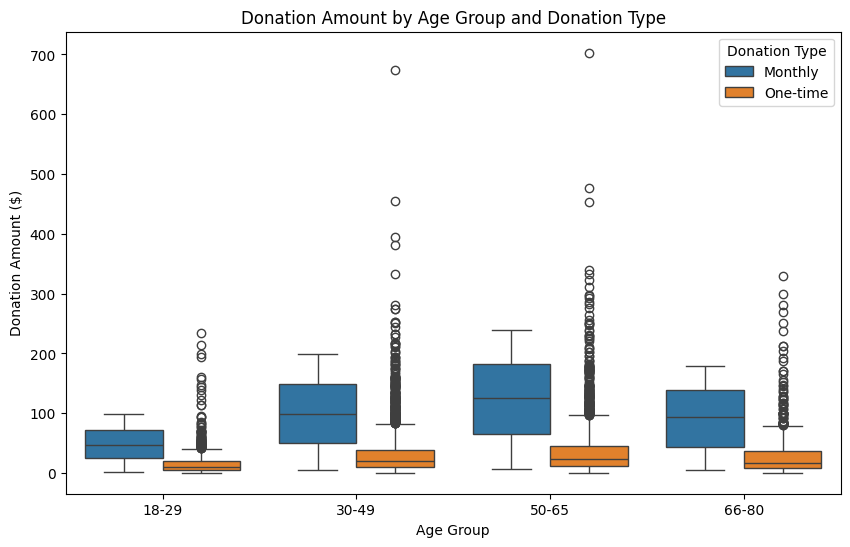

In [31]:
#multivariate EDA
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="age_group",
    y="donation_amount",
    hue="donation_type",
    order=["18-29", "30-49", "50-65", "66-80"]
)

plt.title("Donation Amount by Age Group and Donation Type")
plt.xlabel("Age Group")
plt.ylabel("Donation Amount ($)")
plt.legend(title="Donation Type")
plt.show()

Looking at age group, donation amount, and donation type together provides a clearer picture of donor behavior. Across all age groups, monthly donors generally have higher donation amounts than one-time donors. Donation amounts also appear to increase from the 18-29 group into the middle and older age groups, especially for monthly donors. The 50-65 group appears to have the highest typical monthly donation amounts. However, one-time donors in every age group also contain several high-value outliers. This supports the correlation results. Age has only a weak relationship with donation amount and almost no relationship with monthly donor status, while donation amount has a much stronger relationship with monthly giving.

Hypothesis Review: 
My hypothesis was that donor characteristics, engagement, and donation behavior may help predict whether someone is a monthly donor rather than a one-time donor. Based on the EDA, this hypothesis is partially supported. The strongest evidence comes from donation amount. Monthly donors generally have higher donation amounts than one-time donors, and donation amount has a correlation of 0.55 with monthly donor status. This suggests that donation amount may be useful for predicting the target. However, several other variables showed much weaker relationships. Newsletter participation and age group both had correlations of approximately 0.01 with monthly donor status. Referral channels and campaigns also showed similar monthly-donor percentages across their categories. Therefore, the EDA suggests that some donor behaviors may be useful for predicting monthly giving, but not every donor characteristic appears equally useful.

My Model Strategy based off this EDA: The EDA gives me a better idea of how I should approach the predictive modeling stage. Donation amount appears to be one of the most useful features because it has the strongest relationship with monthly donor status. Other categorical variables, such as age group, referral channel, campaign, payment method, and newsletter participation, can still be tested to determine whether they provide additional predictive value when combined. The target variable is somewhat imbalanced because about 71% of the records are one-time donations and 29% are monthly donations. Because of this, I don't think I should rely only on accuracy when evaluating future models. Metrics such as precision, recall, F1-score, and a confusion matrix will provide a better understanding of model performance. I will also exclude identifying variables such as donor ID, name, and email because they describe individual donors rather than meaningful donor behavior- and that's not necessarily needed right now (I'm looking at characteristics for donor churn not reaching out to donors right now). Finally, the large outliers in donation amount should be considered during modeling rather than automatically removed because they may represent legitimate high-value donors.

Conclusion: This EDA helped me better understand the donor dataset and determine which features may be useful for predicting monthly donor behavior. One of the clearest findings was the relationship between donation amount and donation type. Monthly donors generally gave higher amounts, and donation amount had a correlation of 0.55 with monthly donor status. In comparison, age group and newsletter participation had very weak relationships with the target. Referral channel and campaign also showed only small differences in the percentage of monthly donors. The EDA also identified several large donation outliers, especially among one-time donors. I chose not to remove these values because they may represent legitimate large donations. Overall, my hypothesis was partially supported. Some donor behavior, particularly donation amount, appears related to monthly giving, while several other donor characteristics show weaker relationships. These findings will help guide feature selection and model evaluation during the next stage of the project.

Reference: Zhu, W. (2025, June 18). Animal Charity: Wildlife Conservation Donations. Kaggledatasets. https://www.kaggle.com/datasets/jaderz/synthetic-animal-charity-donations

Milestone 3 START: To continue my work on this dataset, I am continuing with the Animal Charity donation dataset used in Milestone 2. The goal of feature engineering is to prepare the existing variables so they can be used more effectively in a predictive model. Based on my EDA, the target variable will remain whether a donor is a monthly donor or a one-time donor. This makes the project a classification problem because the model will predict one of two categories instead of predicting a continuous numerical value. During this stage, I will review missing values, remove variables that should not be used as predictive features, create a categorical donation amount feature, encode categorical variables, and prepare separate versions of the data for possible logistic regression and decision tree classification models.

I'm going to reload everything by using the kernel restart and run all feature

In [32]:
#confirm missing values
df.isnull().sum()

donor_id              0
age_group             0
gender                0
name                  0
email                 0
country               0
donation_type         0
donation_amount       0
donation_date         0
payment_method        0
newsletter_opt_in     0
referral_channel      0
sector                0
campaign              0
donation_year         0
donation_month        0
donation_dayofweek    0
monthly_donor         0
newsletter_numeric    0
age_group_numeric     0
dtype: int64

In Milestone 2, I checked the dataset for missing values and found that none of the variables contained missing data. I confirmed this again before continuing with feature engineering for Milestone 3. Since there are no missing values, I do not need to use replace the missing values with mean or median.

In [33]:
#create a separate dataframe for feature engineering and modeling
model_df = df.copy()

#remove identifying variables
model_df = model_df.drop(
    columns=["donor_id", "name", "email"]
)

model_df.head()

,age_group,gender,country,donation_type,donation_amount,donation_date,payment_method,newsletter_opt_in,referral_channel,sector,campaign,donation_year,donation_month,donation_dayofweek,monthly_donor,newsletter_numeric,age_group_numeric
0,50-65,Female,UK,Monthly,115.31,2024-10-24,Paypal,False,Website,Real Estate,Rescue Orphaned Gorillas,2024,10,Thursday,1,0,3
1,50-65,Female,USA,One-time,8.60,2024-06-21,Bank Transfer,False,Online advertising,Logistics,Rescue Orphaned Gorillas,2024,6,Friday,0,0,3
2,50-65,Female,USA,One-time,40.07,2024-08-21,Bank Transfer,False,Online advertising,Media & Communication,Marine Mammal Defense Mission,2024,8,Wednesday,0,0,3
3,18-29,Male,USA,One-time,45.17,2023-10-09,Bank Transfer,False,Online advertising,Government,Wildlife Rescue Van Drive,2023,10,Monday,0,0,1
4,30-49,Female,UK,One-time,85.84,2024-09-01,Bank Transfer,True,Newsletter,Science & Research,Habitat for Hope,2024,9,Sunday,0,1,2


I removed identifiers: The donor ID, name, and email variables are useful for identifying individual donor records, but they are not meaningful predictive features for this project. I am looking for characteristics or patterns from donors not specific donors' giving patterns. Including these variables could add unnecessary information to the model without describing the donor's behavior. I created a separate modeling DataFrame and removed these identifying variables while keeping the original DataFrame unchanged.

In [34]:
#remove original donation date
model_df = model_df.drop(columns=["donation_date"])

model_df.head()

,age_group,gender,country,donation_type,donation_amount,payment_method,newsletter_opt_in,referral_channel,sector,campaign,donation_year,donation_month,donation_dayofweek,monthly_donor,newsletter_numeric,age_group_numeric
0,50-65,Female,UK,Monthly,115.31,Paypal,False,Website,Real Estate,Rescue Orphaned Gorillas,2024,10,Thursday,1,0,3
1,50-65,Female,USA,One-time,8.60,Bank Transfer,False,Online advertising,Logistics,Rescue Orphaned Gorillas,2024,6,Friday,0,0,3
2,50-65,Female,USA,One-time,40.07,Bank Transfer,False,Online advertising,Media & Communication,Marine Mammal Defense Mission,2024,8,Wednesday,0,0,3
3,18-29,Male,USA,One-time,45.17,Bank Transfer,False,Online advertising,Government,Wildlife Rescue Van Drive,2023,10,Monday,0,0,1
4,30-49,Female,UK,One-time,85.84,Bank Transfer,True,Newsletter,Science & Research,Habitat for Hope,2024,9,Sunday,0,1,2


In Milestone 2, I converted the original donation date into year, month, and day-of-week features. These variables provide the model with information about when the donation occurred without requiring the model to use the original calendar date. Because these new features already represent the useful parts of the donation date, I removed the original "donation_date" from the modeling dataset.

In [35]:
#find the 25th and 75th percentile donation amounts
q1 = model_df["donation_amount"].quantile(0.25)
q3 = model_df["donation_amount"].quantile(0.75)

print("25th percentile:", q1)
print("75th percentile:", q3)

25th percentile: 12.07
75th percentile: 71.5925


In [36]:
#create donation amount categories
model_df["donation_level"] = pd.cut(
    model_df["donation_amount"],
    bins=[-np.inf, q1, q3, np.inf],
    labels=["Low", "Medium", "High"]
)

model_df[["donation_amount", "donation_level"]].head(10)

,donation_amount,donation_level
0,115.31,High
1,8.60,Low
2,40.07,Medium
3,45.17,Medium
4,85.84,High
5,293.22,High
6,15.00,Medium
7,93.42,High
8,19.46,Medium
9,209.59,High


I created donation amount categories to make the donation values easier to compare. Instead of choosing random donation amounts for Low, Medium, and High, I used the data to set the cutoffs. The 25th percentile means about 25% of the donations were below that amount, and the 75th percentile means about 75% of the donations were below that amount. Donations below the 25th percentile were labeled Low, donations between the 25th and 75th percentiles were labeled Medium, and donations above the 75th percentile were labeled High. This can be helpful because the donation amounts were not evenly spread out, and a few donations were much larger than the rest. So having a range can help determine a pattern in the future. 

In [37]:
#review categories
model_df["donation_level"].value_counts()

donation_level
Medium    4996
Low       2504
High      2500
Name: count, dtype: int64

I reviewed the new donation category level feature to make sure the numerical donation amounts were placed into the expected categories. The Medium level seems high but it also accounts for all donation records between the 25th and 75th percentile so that seems like its expected. 

In [38]:
#separate the target variable
#define target
y = model_df["monthly_donor"]

#define predictor variables
X = model_df.drop(
    columns=[
        "monthly_donor",
        "donation_type"
    ]
)

print("Predictor shape:", X.shape)
print("Target shape:", y.shape)

Predictor shape: (10000, 15)
Target shape: (10000,)


The target variable for this project is "monthly_donor" from "donation_type", which was done in Milestone 2. Because "donation_type" directly affects whether "monthly_donor" equals 0 or 1, I removed "donation_type" from the predictor variables. This just ensures it won't be a factor is creating any misinterpretations.

In [39]:
#Remove duplicate features
#show all features
X.columns.tolist()

['age_group',
 'gender',
 'country',
 'donation_amount',
 'payment_method',
 'newsletter_opt_in',
 'referral_channel',
 'sector',
 'campaign',
 'donation_year',
 'donation_month',
 'donation_dayofweek',
 'newsletter_numeric',
 'age_group_numeric',
 'donation_level']

In [40]:
#remove duplicates from EDA
X = X.drop(
    columns=[
        "age_group_numeric",
        "newsletter_numeric"
    ]
)

X.head()

,age_group,gender,country,donation_amount,payment_method,newsletter_opt_in,referral_channel,sector,campaign,donation_year,donation_month,donation_dayofweek,donation_level
0,50-65,Female,UK,115.31,Paypal,False,Website,Real Estate,Rescue Orphaned Gorillas,2024,10,Thursday,High
1,50-65,Female,USA,8.60,Bank Transfer,False,Online advertising,Logistics,Rescue Orphaned Gorillas,2024,6,Friday,Low
2,50-65,Female,USA,40.07,Bank Transfer,False,Online advertising,Media & Communication,Marine Mammal Defense Mission,2024,8,Wednesday,Medium
3,18-29,Male,USA,45.17,Bank Transfer,False,Online advertising,Government,Wildlife Rescue Van Drive,2023,10,Monday,Medium
4,30-49,Female,UK,85.84,Bank Transfer,True,Newsletter,Science & Research,Habitat for Hope,2024,9,Sunday,High


In Milestone 2, I created numerical versions of age group and newsletter participation so they could be included in a correlation matrix. But for the predictive model, I don't need both the original variable and its numerical version because that would represent the same information twice. I removed "age_group" and "newsletter" numeric versions from the predictor dataset and will include only the original variables instead.

In [41]:
#convert boolean variable to 0 and 1
X["newsletter_opt_in"] = X["newsletter_opt_in"].astype(int)

X["newsletter_opt_in"].value_counts()

newsletter_opt_in
0    5008
1    4992
Name: count, dtype: int64

The "newsletter_opt_in" variable contains True and False values. I converted these values into 1 and 0 so that it can be used directly by machine learning algorithms.

In [42]:
#identify categorical predictor variables
categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns

categorical_features.tolist()

['age_group',
 'gender',
 'country',
 'payment_method',
 'referral_channel',
 'sector',
 'campaign',
 'donation_dayofweek',
 'donation_level']

Most of the remaining predictor variables are categorical. Before using these variables in a machine learning model, they all need to be in numerical form so I need to convert these remaining ones into numerical form.

In [43]:
#one-hot encoding 
X_encoded = pd.get_dummies(
    X,
    columns=categorical_features,
    drop_first=True,
    dtype=int
)

X_encoded.head()

,donation_amount,newsletter_opt_in,donation_year,donation_month,age_group_30-49,age_group_50-65,age_group_66-80,gender_Male,gender_Other,country_Brazil,country_Canada,country_Finland,country_France,country_Germany,country_India,country_Netherlands,country_New Zealand,country_South Africa,country_UK,country_USA,payment_method_Cheque,payment_method_Credit Card,payment_method_Paypal,referral_channel_Newsletter,referral_channel_Online advertising,referral_channel_Social Media,referral_channel_Website,referral_channel_Word of mouth,sector_Arts & Culture,sector_Construction,sector_Consulting,sector_Education,sector_Energy,sector_Environment,sector_Finance/Banking,sector_Government,sector_Healthcare,sector_Hospitality,sector_Law,sector_Logistics,sector_Media & Communication,sector_Nonprofit,sector_Others,sector_Pharmaceuticals,sector_Real Estate,sector_Retail,sector_Science & Research,sector_Technology,campaign_Habitat for Hope,campaign_Jungle Education Project,campaign_Marine Mammal Defense Mission,campaign_Reforest the Sanctuary,campaign_Rescue Orphaned Gorillas,campaign_Wildlife Rescue Van Drive,donation_dayofweek_Monday,donation_dayofweek_Saturday,donation_dayofweek_Sunday,donation_dayofweek_Thursday,donation_dayofweek_Tuesday,donation_dayofweek_Wednesday,donation_level_Medium,donation_level_High
0,115.31,0,2024,10,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,1
1,8.60,0,2024,6,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0
2,40.07,0,2024,8,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,1,0
3,45.17,0,2023,10,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,1,0
4,85.84,1,2024,9,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,1,0,0,0,0,1


I used one-hot encoding to convert categorical predictors into numerical variables. One-hot encoding creates separate 0 or 1 columns for the categories without assuming that one category is mathematically greater than another. This is useful for variables such as gender, country, payment method, referral channel, sector, campaign, and donation level- simple, clear and to the point.

In [44]:
#check the final predictor data
#review structure of encoded predictors
X_encoded.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 62 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   donation_amount                         10000 non-null  float64
 1   newsletter_opt_in                       10000 non-null  int64  
 2   donation_year                           10000 non-null  int32  
 3   donation_month                          10000 non-null  int32  
 4   age_group_30-49                         10000 non-null  int64  
 5   age_group_50-65                         10000 non-null  int64  
 6   age_group_66-80                         10000 non-null  int64  
 7   gender_Male                             10000 non-null  int64  
 8   gender_Other                            10000 non-null  int64  
 9   country_Brazil                          10000 non-null  int64  
 10  country_Canada                          10000 non-null  int

In [45]:
#check for remaining missing values
X_encoded.isnull().sum().sum()

np.int64(0)

I checked the final data, and it seems no missing values so the final predictor data looks good! 

In [46]:
#review target distribution
print(y.value_counts())

print("\nPercentages:")
print((y.value_counts(normalize=True) * 100).round(2))

monthly_donor
0    7085
1    2915
Name: count, dtype: int64

Percentages:
monthly_donor
0    70.85
1    29.15
Name: proportion, dtype: float64


So to review the classification target: Before modeling, I reviewed the distribution of the classification target. The dataset contains more one-time donors (7085 or 70.85%) than monthly donors (2915 or 29.15%), so the target is somewhat imbalanced. This is important because accuracy alone may not be enough to evaluate a future classification model. I may also need to use precision, recall, F1-score, and a confusion matrix.

In [47]:
#prepare for different classifications
#import libraries
from sklearn.preprocessing import StandardScaler

In [48]:
#create a copy for logistic regression
X_logistic = X_encoded.copy()

#create scaler
scaler = StandardScaler()

#standardize donation amount
X_logistic[["donation_amount"]] = scaler.fit_transform(
    X_logistic[["donation_amount"]]
)

X_logistic[["donation_amount"]].head()

,donation_amount
0,1.121080
1,-0.759518
2,-0.204908
3,-0.115028
4,0.601717


In [49]:
#create an unscaled copy for decision tree classification
X_tree = X_encoded.copy()

X_tree.head()

,donation_amount,newsletter_opt_in,donation_year,donation_month,age_group_30-49,age_group_50-65,age_group_66-80,gender_Male,gender_Other,country_Brazil,country_Canada,country_Finland,country_France,country_Germany,country_India,country_Netherlands,country_New Zealand,country_South Africa,country_UK,country_USA,payment_method_Cheque,payment_method_Credit Card,payment_method_Paypal,referral_channel_Newsletter,referral_channel_Online advertising,referral_channel_Social Media,referral_channel_Website,referral_channel_Word of mouth,sector_Arts & Culture,sector_Construction,sector_Consulting,sector_Education,sector_Energy,sector_Environment,sector_Finance/Banking,sector_Government,sector_Healthcare,sector_Hospitality,sector_Law,sector_Logistics,sector_Media & Communication,sector_Nonprofit,sector_Others,sector_Pharmaceuticals,sector_Real Estate,sector_Retail,sector_Science & Research,sector_Technology,campaign_Habitat for Hope,campaign_Jungle Education Project,campaign_Marine Mammal Defense Mission,campaign_Reforest the Sanctuary,campaign_Rescue Orphaned Gorillas,campaign_Wildlife Rescue Van Drive,donation_dayofweek_Monday,donation_dayofweek_Saturday,donation_dayofweek_Sunday,donation_dayofweek_Thursday,donation_dayofweek_Tuesday,donation_dayofweek_Wednesday,donation_level_Medium,donation_level_High
0,115.31,0,2024,10,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,1
1,8.60,0,2024,6,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0
2,40.07,0,2024,8,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,1,0
3,45.17,0,2023,10,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,1,0
4,85.84,1,2024,9,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,1,0,0,0,0,1


The amount of feature engineering needed can depend on the algorithm being used. I am considering logistic regression and decision tree classification. Logistic regression can benefit from numerical variables being standardized so that features measured on different scales are more comparable. Decision trees generally do not require feature scaling. However, I will keep the original encoded feature set for a possible decision tree model and create a second scaled version that could be used with logistic regression. 

In [50]:
#compare original and standardized donation amount
scaling_comparison = pd.DataFrame({
    "Original Donation Amount": X_encoded["donation_amount"].head(10),
    "Standardized Donation Amount": X_logistic["donation_amount"].head(10)
})

scaling_comparison

,Original Donation Amount,Standardized Donation Amount
0,115.31,1.121080
1,8.60,-0.759518
2,40.07,-0.204908
3,45.17,-0.115028
4,85.84,0.601717
5,293.22,4.256468
6,15.00,-0.646728
7,93.42,0.735303
8,19.46,-0.568127
9,209.59,2.782619


When comparing the the original and standardized donation amounts: The original donation amount is measured in dollars, while the standardized version is centered around zero and measured in standard deviations from the mean. The underlying donor information has not changed. Standardization only changes the scale of the numerical variable. The standardized verison may be better suited for visuals. 

In [51]:
#final feature engineering check
print("Decision Tree Feature Shape:", X_tree.shape)
print("Logistic Regression Feature Shape:", X_logistic.shape)
print("Target Shape:", y.shape)

print("\nMissing values in decision tree data:",
      X_tree.isnull().sum().sum())

print("Missing values in logistic regression data:",
      X_logistic.isnull().sum().sum())

Decision Tree Feature Shape: (10000, 62)
Logistic Regression Feature Shape: (10000, 62)
Target Shape: (10000,)

Missing values in decision tree data: 0
Missing values in logistic regression data: 0


After completing feature engineering, I reviewed the final predictor and target datasets. The predictor variables are now numerical and ready for future classification modeling. The target remains separate from the predictors, identifying variables have been removed, and the original "donation_type" variable was excluded to prevent target leakage.

To conclude Milestone 3, I performed additional feature engineering to prepare the Animal Charity donation dataset from Kaggle for future classification modeling. Since Milestone 2 showed that the dataset did not contain any missing values or duplicate records, no missing-value replacement was necessary. I removed identifying variables because they describe individual records rather than meaningful donor behavior, which is what I ultimately want the model to focus on. I also removed the original donation date because I had already created separate year, month, and day-of-week features from it.I created a new donation-level feature by grouping donation amounts into Low, Medium, and High categories based on the distribution of the data. I also converted categorical variables using one-hot encoding and kept the monthly donor variable separate as the classification target. I am still considering comparing logistic regression and decision tree classification in future milestones, so I created two versions of the feature data. The logistic regression version includes standardized donation amounts, while the decision tree version keeps the original numerical scale. Overall, it was interesting to see how feature engineering can prepare a dataset for classification modeling while also removing unnecessary variables and helping prevent issues such as target leakage.

Milestone 4 Start

For this milestone, I am continuing with the feature-engineered Animal Charity donation dataset from Milestone 3. The target variable is "monthly_donor", where 0 represents a one-time donor and 1 represents a monthly donor. Since the goal is to predict one of these two categories, this is a binary classification problem. For this portion of the project, I will build and compare two classification models: logistic regression and a decision tree. I will first create baseline versions of each model, evaluate their performance, use cross-validation and hyperparameter tuning, and then compare the tuned models to determine which one performs better.

In [52]:
#import modeling and evaluation tools
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    GridSearchCV
)

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

from sklearn.dummy import DummyClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

import matplotlib.pyplot as plt
import pandas as pd

I imported the tools needed to split the data, build the classification models, perform cross-validation and hyperparameter tuning, and evaluate model performance. I will use logistic regression and decision tree classification because both are appropriate for a binary classification problem.

In [53]:
#split the encoded predictors and target into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Training feature shape: (8000, 62)
Testing feature shape: (2000, 62)
Training target shape: (8000,)
Testing target shape: (2000,)


I split the dataset into 80/20% testing data. I used stratification so the percentage of one-time and monthly donors stays similar in both datasets. I also started from the encoded feature dataset instead of the standardized version created in Milestone 3. This allows any scaling needed for logistic regression to happen only after the data is split, which helps prevent information from the testing data from influencing the training process.

In [56]:
#review target distribution in training and testing data
print("Training Target Percentages:")
print(
    (y_train.value_counts(normalize=True) * 100).round(2)
)

print("\nTesting Target Percentages:")
print(
    (y_test.value_counts(normalize=True) * 100).round(2)
)

Training Target Percentages:
monthly_donor
0    70.85
1    29.15
Name: proportion, dtype: float64

Testing Target Percentages:
monthly_donor
0    70.85
1    29.15
Name: proportion, dtype: float64


The training and testing datasets have the same target distribution. About 70.85% of the records are class 0, or one-time donors, and 29.15% are class 1, or monthly donors. This confirms that using stratification worked correctly because the class proportions stayed consistent after splitting the data. The target is somewhat imbalanced since one-time donors make up most of the records, so I will keep that in mind when comparing model performance.

In [57]:
#create majority-class baseline
baseline_model = DummyClassifier(
    strategy="most_frequent"
)

baseline_model.fit(
    X_train,
    y_train
)

baseline_pred = baseline_model.predict(
    X_test
)

baseline_accuracy = accuracy_score(
    y_test,
    baseline_pred
)

print(
    "Majority-Class Baseline Accuracy:",
    round(baseline_accuracy, 4)
)

Majority-Class Baseline Accuracy: 0.7085


The majority-class baseline accuracy was 0.7085, or 70.85%. This makes sense because class 0, representing one-time donors, also makes up 70.85% of the dataset. This baseline gives me a simple comparison point for the other models. Any useful classification model should ideally perform better than 70.85% accuracy instead of just predicting the most common class every time.

In [58]:
#create logistic regression pipeline
logistic_model = Pipeline([
    (
        "scaler",
        StandardScaler()
    ),
    (
        "classifier",
        LogisticRegression(
            max_iter=2000,
            random_state=42
        )
    )
])

#train baseline logistic regression model
logistic_model.fit(
    X_train,
    y_train
)

#generate predictions
logistic_pred = logistic_model.predict(
    X_test
)

logistic_prob = logistic_model.predict_proba(
    X_test
)[:, 1]

print("Baseline logistic regression model complete.")

Baseline logistic regression model complete.


I first built a logistic regression model. I used a pipeline so that standardization occurs during the modeling process instead of before the train/test split. This helps prevent data leakage because the scaler learns its values from the training data rather than the entire dataset.

In [59]:
#calculate logistic regression metrics
logistic_accuracy = accuracy_score(
    y_test,
    logistic_pred
)

logistic_precision = precision_score(
    y_test,
    logistic_pred,
    zero_division=0
)

logistic_recall = recall_score(
    y_test,
    logistic_pred,
    zero_division=0
)

logistic_f1 = f1_score(
    y_test,
    logistic_pred,
    zero_division=0
)

logistic_auc = roc_auc_score(
    y_test,
    logistic_prob
)

print("Baseline Logistic Regression")
print("----------------------------")
print(f"Accuracy:  {logistic_accuracy:.4f}")
print(f"Precision: {logistic_precision:.4f}")
print(f"Recall:    {logistic_recall:.4f}")
print(f"F1-Score:  {logistic_f1:.4f}")
print(f"ROC-AUC:   {logistic_auc:.4f}")

Baseline Logistic Regression
----------------------------
Accuracy:  0.8135
Precision: 0.7293
Recall:    0.5729
F1-Score:  0.6417
ROC-AUC:   0.8411


The baseline logistic regression model performed much better than the majority-class baseline. Its accuracy was 0.8135 compared with the baseline accuracy of 0.7085. The ROC-AUC score was also strong at 0.8411, which shows that the model does a good job separating one-time donors from monthly donors. Precision was 0.7293, while recall was lower at 0.5729, meaning the model is more accurate when it predicts a monthly donor than it is at finding all of the actual monthly donors. Overall, the logistic regression model is showing useful predictive performance, but there is still room to improve recall and F1-score.

In [60]:
#classification report for baseline logistic regression
print(
    classification_report(
        y_test,
        logistic_pred,
        zero_division=0
    )
)

              precision    recall  f1-score   support

           0       0.84      0.91      0.87      1417
           1       0.73      0.57      0.64       583

    accuracy                           0.81      2000
   macro avg       0.78      0.74      0.76      2000
weighted avg       0.81      0.81      0.81      2000



The classification report shows that the model performs much better for class 0 than class 1. For class 0, recall was 0.91 and the F1-score was 0.87, which means the model correctly identified most one-time donors. For class 1, recall was lower at 0.57 and the F1-score was 0.64, so the model still missed some monthly donors. Overall accuracy was about 0.81. This confirms that logistic regression is performing well overall, but identifying monthly donors is still the more difficult part of the classification problem.

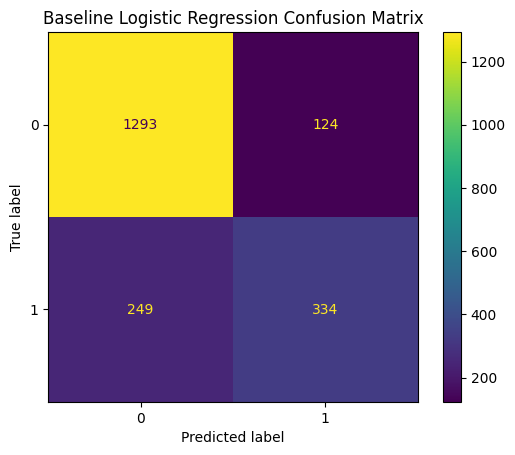

In [61]:
#create logistic regression confusion matrix
logistic_cm = confusion_matrix(
    y_test,
    logistic_pred
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=logistic_cm,
    display_labels=[0, 1]
)

disp.plot(values_format="d")

plt.title(
    "Baseline Logistic Regression Confusion Matrix"
)

plt.show()

The confusion matrix shows that the model correctly predicted 1,293 one-time donors and 334 monthly donors. It incorrectly predicted 124 one-time donors as monthly and missed 249 monthly donors by predicting them as one-time. This matches the classification report because the model is much better at identifying class 0 than class 1. The largest issue is the 249 false negatives, which shows that some monthly donors are still being missed.

In [62]:
#create baseline decision tree
tree_model = DecisionTreeClassifier(
    random_state=42
)

#train the model
tree_model.fit(
    X_train,
    y_train
)

#make predictions
tree_pred = tree_model.predict(
    X_test
)

tree_prob = tree_model.predict_proba(
    X_test
)[:, 1]

print("Baseline decision tree model complete.")

Baseline decision tree model complete.


I created a decision tree classifier so I could compare a second classification algorithm with logistic regression. The decision tree does not require feature scaling, so I used the encoded training data directly. This gives me another model to compare and may help show whether a different algorithm can identify patterns that logistic regression misses.

In [63]:
#calculate decision tree metrics
tree_accuracy = accuracy_score(
    y_test,
    tree_pred
)

tree_precision = precision_score(
    y_test,
    tree_pred,
    zero_division=0
)

tree_recall = recall_score(
    y_test,
    tree_pred,
    zero_division=0
)

tree_f1 = f1_score(
    y_test,
    tree_pred,
    zero_division=0
)

tree_auc = roc_auc_score(
    y_test,
    tree_prob
)

print("Baseline Decision Tree")
print("----------------------")
print(f"Accuracy:  {tree_accuracy:.4f}")
print(f"Precision: {tree_precision:.4f}")
print(f"Recall:    {tree_recall:.4f}")
print(f"F1-Score:  {tree_f1:.4f}")
print(f"ROC-AUC:   {tree_auc:.4f}")

Baseline Decision Tree
----------------------
Accuracy:  0.7310
Precision: 0.5378
Recall:    0.5489
F1-Score:  0.5433
ROC-AUC:   0.6774


The baseline decision tree had an accuracy of 0.7310, which is lower than the logistic regression model. Precision was 0.5378, recall was 0.5489, and the F1-score was 0.5433. The ROC-AUC score was 0.6774. The decision tree performed better than the majority-class baseline, but it did not perform as well as logistic regression. This suggests that logistic regression is currently the stronger model for this dataset, although I still want to review the decision tree classification report and confusion matrix before tuning both models.

In [64]:
#classification report for baseline decision tree
print(
    classification_report(
        y_test,
        tree_pred,
        zero_division=0
    )
)

              precision    recall  f1-score   support

           0       0.81      0.81      0.81      1417
           1       0.54      0.55      0.54       583

    accuracy                           0.73      2000
   macro avg       0.68      0.68      0.68      2000
weighted avg       0.73      0.73      0.73      2000



The decision tree performed better on class 0 than class 1. For class 0, precision, recall, and F1-score were all about 0.81. For class 1, the results were much lower, with precision at 0.54, recall at 0.55, and an F1-score of 0.54. Overall accuracy was about 0.73. Compared with logistic regression, the decision tree performed worse overall and was also weaker at identifying monthly donors in class 1.

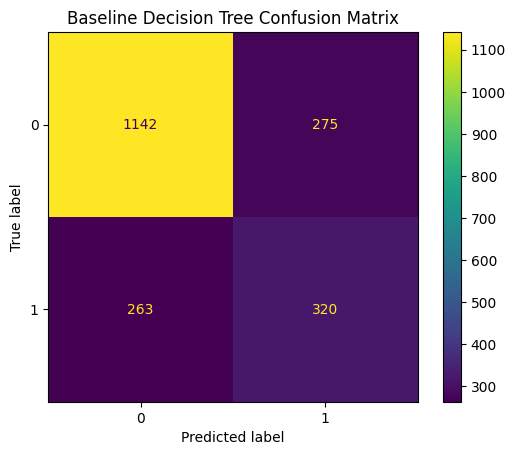

In [65]:
#create decision tree confusion matrix
tree_cm = confusion_matrix(
    y_test,
    tree_pred
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=tree_cm,
    display_labels=[0, 1]
)

disp.plot(values_format="d")

plt.title(
    "Baseline Decision Tree Confusion Matrix"
)

plt.show()

The decision tree correctly predicted 1,142 one-time donors and 320 monthly donors. It incorrectly classified 275 one-time donors as monthly and missed 263 monthly donors by predicting them as one-time. Compared with logistic regression, the decision tree made more errors overall. This supports the earlier results showing that logistic regression is currently the stronger model for this dataset.

In [66]:
#compare baseline models
baseline_comparison = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC"
    ],
    "Logistic Regression": [
        logistic_accuracy,
        logistic_precision,
        logistic_recall,
        logistic_f1,
        logistic_auc
    ],
    "Decision Tree": [
        tree_accuracy,
        tree_precision,
        tree_recall,
        tree_f1,
        tree_auc
    ]
})

display(
    baseline_comparison.round(4)
)

,Metric,Logistic Regression,Decision Tree
0,Accuracy,0.8135,0.7310
1,Precision,0.7293,0.5378
2,Recall,0.5729,0.5489
3,F1-Score,0.6417,0.5433
4,ROC-AUC,0.8411,0.6774


The comparison shows that logistic regression performed better than the decision tree across all of the evaluation metrics. Logistic regression had higher accuracy, precision, recall, F1-score, and ROC-AUC. The largest differences were in precision and ROC-AUC, which suggests that logistic regression is doing a better job identifying monthly donors and separating the two classes overall. At this point, logistic regression is the stronger baseline model, but I still want to tune both models to see whether either one can improve.

In [67]:
#create stratified 5-fold cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print(
    "5-fold stratified cross-validation created."
)

5-fold stratified cross-validation created.


I created 5-fold stratified cross-validation for the hyperparameter tuning process. Using stratification helps keep a similar percentage of one-time and monthly donors in each fold. This is important because the target is somewhat imbalanced.

In [68]:
#create logistic regression parameter grid
logistic_param_grid = {
    "classifier__C": [
        0.01,
        0.1,
        1,
        10,
        100
    ],
    "classifier__penalty": [
        "l1",
        "l2"
    ],
    "classifier__solver": [
        "liblinear"
    ],
    "classifier__class_weight": [
        None,
        "balanced"
    ]
}

#create grid search
logistic_grid = GridSearchCV(
    estimator=logistic_model,
    param_grid=logistic_param_grid,
    cv=cv,
    scoring="f1",
    n_jobs=-1
)

#fit using training data
logistic_grid.fit(
    X_train,
    y_train
)

print("Best Logistic Regression Parameters:")
print(logistic_grid.best_params_)

print(
    "\nBest Logistic Regression CV F1:",
    round(logistic_grid.best_score_, 4)
)

Best Logistic Regression Parameters:
{'classifier__C': 0.1, 'classifier__class_weight': 'balanced', 'classifier__penalty': 'l1', 'classifier__solver': 'liblinear'}

Best Logistic Regression CV F1: 0.6916


The best logistic regression settings used a C value of 0.1, balanced class weights, an L1 penalty, and the liblinear solver. The best cross-validation F1-score was 0.6916. This is higher than the baseline logistic regression F1-score of 0.6417, so the tuning results suggest that the adjusted model may do a better job balancing precision and recall. The balanced class weight may also help because monthly donors are the smaller class in the dataset. I still need to test the tuned model on the separate test data to see whether this improvement carries over to new observations.

In [69]:
#create decision tree parameter grid
tree_param_grid = {
    "max_depth": [
        3,
        5,
        10,
        None
    ],
    "min_samples_split": [
        2,
        10,
        25
    ],
    "min_samples_leaf": [
        1,
        5,
        10
    ],
    "criterion": [
        "gini",
        "entropy"
    ],
    "class_weight": [
        None,
        "balanced"
    ]
}

#create GridSearchCV for decision tree
tree_grid = GridSearchCV(
    estimator=tree_model,
    param_grid=tree_param_grid,
    cv=cv,
    scoring="f1",
    n_jobs=-1
)

#fit using the training data
tree_grid.fit(
    X_train,
    y_train
)

print("Best Decision Tree Parameters:")
print(tree_grid.best_params_)

print(
    "\nBest Decision Tree CV F1:",
    round(tree_grid.best_score_, 4)
)

Best Decision Tree Parameters:
{'class_weight': 'balanced', 'criterion': 'gini', 'max_depth': 5, 'min_samples_leaf': 10, 'min_samples_split': 2}

Best Decision Tree CV F1: 0.6894


The best decision tree used balanced class weights, the Gini criterion, a maximum depth of 5, a minimum leaf size of 10, and a minimum split size of 2. The best cross-validation F1-score was 0.6894. This is much higher than the baseline decision tree F1-score of 0.5433, so the tuning results suggest that limiting the tree depth and balancing the classes helped improve the model. The next step I'm going to do is to test the tuned decision tree on the separate test data to see whether this improvement holds up on new observations.

In [70]:
#get the best tuned logistic regression model
tuned_logistic = logistic_grid.best_estimator_

#make predictions on the test data
tuned_logistic_pred = tuned_logistic.predict(
    X_test
)

#get predicted probabilities for class 1
tuned_logistic_prob = tuned_logistic.predict_proba(
    X_test
)[:, 1]

#calculate evaluation metrics
tuned_logistic_accuracy = accuracy_score(
    y_test,
    tuned_logistic_pred
)

tuned_logistic_precision = precision_score(
    y_test,
    tuned_logistic_pred,
    zero_division=0
)

tuned_logistic_recall = recall_score(
    y_test,
    tuned_logistic_pred,
    zero_division=0
)

tuned_logistic_f1 = f1_score(
    y_test,
    tuned_logistic_pred,
    zero_division=0
)

tuned_logistic_auc = roc_auc_score(
    y_test,
    tuned_logistic_prob
)

print("Tuned Logistic Regression")
print("-------------------------")
print(f"Accuracy:  {tuned_logistic_accuracy:.4f}")
print(f"Precision: {tuned_logistic_precision:.4f}")
print(f"Recall:    {tuned_logistic_recall:.4f}")
print(f"F1-Score:  {tuned_logistic_f1:.4f}")
print(f"ROC-AUC:   {tuned_logistic_auc:.4f}")

Tuned Logistic Regression
-------------------------
Accuracy:  0.8025
Precision: 0.6506
Recall:    0.6964
F1-Score:  0.6727
ROC-AUC:   0.8475


The tuned logistic regression model had an accuracy of 0.8025, precision of 0.6506, recall of 0.6964, an F1-score of 0.6727, and an ROC-AUC of 0.8475. Compared with the baseline logistic regression, accuracy and precision decreased slightly, but recall improved from 0.5729 to 0.6964 and the F1-score improved from 0.6417 to 0.6727. This tells me that the tuned model is better at finding actual monthly donors, even though it makes a few more incorrect positive predictions. Since monthly donors are the smaller class, the higher recall and F1-score make the tuned model more useful for this classification goal.

In [71]:
#get the best tuned decision tree model
tuned_tree = tree_grid.best_estimator_

#make predictions on the test data
tuned_tree_pred = tuned_tree.predict(
    X_test
)

#get predicted probabilities for class 1
tuned_tree_prob = tuned_tree.predict_proba(
    X_test
)[:, 1]

#calculate evaluation metrics
tuned_tree_accuracy = accuracy_score(
    y_test,
    tuned_tree_pred
)

tuned_tree_precision = precision_score(
    y_test,
    tuned_tree_pred,
    zero_division=0
)

tuned_tree_recall = recall_score(
    y_test,
    tuned_tree_pred,
    zero_division=0
)

tuned_tree_f1 = f1_score(
    y_test,
    tuned_tree_pred,
    zero_division=0
)

tuned_tree_auc = roc_auc_score(
    y_test,
    tuned_tree_prob
)

print("Tuned Decision Tree")
print("-------------------")
print(f"Accuracy:  {tuned_tree_accuracy:.4f}")
print(f"Precision: {tuned_tree_precision:.4f}")
print(f"Recall:    {tuned_tree_recall:.4f}")
print(f"F1-Score:  {tuned_tree_f1:.4f}")
print(f"ROC-AUC:   {tuned_tree_auc:.4f}")

Tuned Decision Tree
-------------------
Accuracy:  0.7885
Precision: 0.6153
Recall:    0.7324
F1-Score:  0.6688
ROC-AUC:   0.8485


The tuned decision tree had an accuracy of 0.7885, precision of 0.6153, recall of 0.7324, an F1-score of 0.6688, and an ROC-AUC of 0.8485. Compared with the baseline decision tree, every metric improved. The biggest change was in recall, which increased from 0.5489 to 0.7324. This means the tuned decision tree is much better at identifying actual monthly donors. Overall, tuning made a major improvement to the decision tree and made it much more competitive with logistic regression.

In [72]:
#compare all models
final_comparison = pd.DataFrame({
    "Model": [
        "Majority Baseline",
        "Baseline Logistic Regression",
        "Tuned Logistic Regression",
        "Baseline Decision Tree",
        "Tuned Decision Tree"
    ],
    "Accuracy": [
        baseline_accuracy,
        logistic_accuracy,
        tuned_logistic_accuracy,
        tree_accuracy,
        tuned_tree_accuracy
    ],
    "Precision": [
        0,
        logistic_precision,
        tuned_logistic_precision,
        tree_precision,
        tuned_tree_precision
    ],
    "Recall": [
        0,
        logistic_recall,
        tuned_logistic_recall,
        tree_recall,
        tuned_tree_recall
    ],
    "F1-Score": [
        0,
        logistic_f1,
        tuned_logistic_f1,
        tree_f1,
        tuned_tree_f1
    ],
    "ROC-AUC": [
        0.5,
        logistic_auc,
        tuned_logistic_auc,
        tree_auc,
        tuned_tree_auc
    ]
})

display(
    final_comparison.round(4)
)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Majority Baseline,0.7085,0.0000,0.0000,0.0000,0.5000
1,Baseline Logistic Regression,0.8135,0.7293,0.5729,0.6417,0.8411
2,Tuned Logistic Regression,0.8025,0.6506,0.6964,0.6727,0.8475
3,Baseline Decision Tree,0.7310,0.5378,0.5489,0.5433,0.6774
4,Tuned Decision Tree,0.7885,0.6153,0.7324,0.6688,0.8485


The final comparison shows that tuning improved both logistic regression and the decision tree, especially when looking at recall and F1-score. The baseline logistic regression had the highest accuracy at 0.8135, but the tuned logistic regression had the highest F1-score at 0.6727. The tuned decision tree had the highest recall at 0.7324 and the highest ROC-AUC at 0.8485. This shows that there is not one model that is best at every metric. Since monthly donors are the smaller class, the tuned models are more useful because they do a better job identifying class 1. Overall, the tuned logistic regression and tuned decision tree performed very similarly, with each having different strengths.

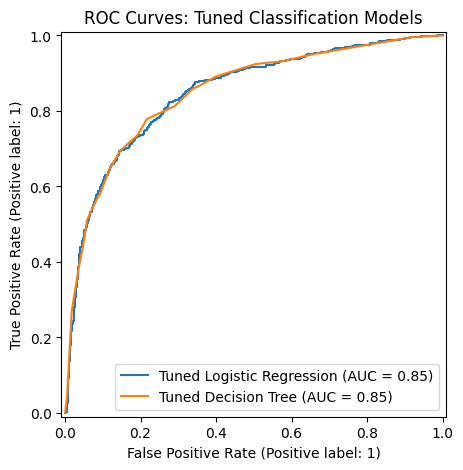

In [73]:
#compare ROC curves for tuned models
fig, ax = plt.subplots(
    figsize=(7, 5)
)

RocCurveDisplay.from_predictions(
    y_test,
    tuned_logistic_prob,
    name="Tuned Logistic Regression",
    ax=ax
)

RocCurveDisplay.from_predictions(
    y_test,
    tuned_tree_prob,
    name="Tuned Decision Tree",
    ax=ax
)

plt.title(
    "ROC Curves: Tuned Classification Models"
)

plt.show()

The ROC curves for the tuned logistic regression and tuned decision tree are almost identical. Both models had an ROC-AUC of about 0.85, which shows that they perform similarly when separating one-time donors from monthly donors. The tuned decision tree had a slightly higher ROC-AUC, but the difference was very small. Based on this graph alone, I would not consider one model clearly better than the other.

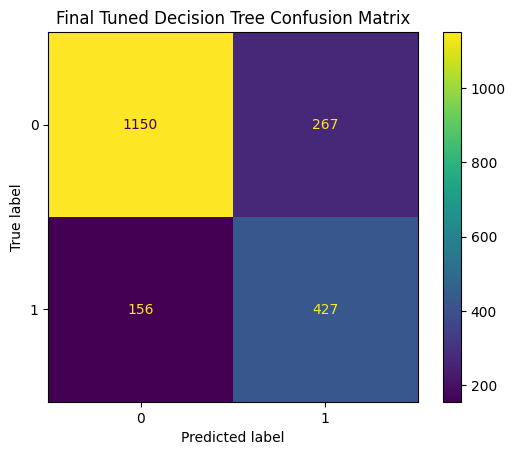

In [74]:
#Create confusion matrix for the tuned decision tree
final_cm = confusion_matrix(
    y_test,
    tuned_tree_pred
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=final_cm,
    display_labels=[0, 1]
)

disp.plot(values_format="d")

plt.title(
    "Final Tuned Decision Tree Confusion Matrix"
)

plt.show()

I selected the tuned decision tree as the final model because it had the highest recall for class 1 at 0.7324. Since monthly donors are the smaller class, I wanted to prioritize a model that could correctly identify more of the actual monthly donors. The final confusion matrix shows that the tuned decision tree correctly predicted 1,150 one-time donors and 427 monthly donors. It incorrectly classified 267 one-time donors as monthly and missed 156 monthly donors by predicting them as one-time. Compared with the baseline decision tree, the tuned model reduced the number of missed monthly donors and improved its ability to identify class 1. Overall, this supports choosing the tuned decision tree when recall for monthly donors is an important goal.

For Milestone 4, I built, evaluated, and tuned both logistic regression and decision tree classification models. Logistic regression was the stronger baseline model, but tuning improved both models, especially the decision tree. The tuned decision tree had the highest recall for monthly donors at 0.7324 and an ROC-AUC of 0.8485, so I selected it as the final model. Overall, this milestone showed me how model tuning and evaluation can change which model is the better choice depending on what goals you have of the prediction.